In [16]:
import matplotlib.pyplot as plt
import polars as pl
from desmin_reconstruction.plotting import save_panel
from desmin_reconstruction.plotting.lineplots import line_and_bandplot
from IPython.display import display, SVG


COLOR_DICT = {"desmin": "#CC3311", "actin": "#0077BB", "actinin": "#009988"}
LS_DICT = {"actin": "-.", "actinin": "-"}
LABEL_DICT = {"desmin": "Desmin", "actin": "Actin", "actinin": "α-actinin"}
scatter_kwargs = {"alpha": 0.3, "s": 0.2}


Text(0, 0.5, 'Probability')

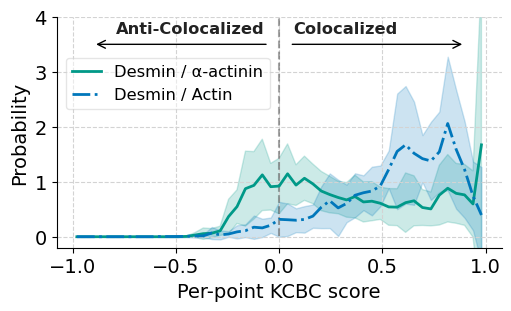

In [17]:
plt.rc("font", size=14)

fig, ax = plt.subplots(1, 1, figsize=(5, 3), constrained_layout=True)
ax.axvline(x=0, ymin=0.05, ymax=3.0, ls="--", color="#222222", alpha=0.4)
for protein, offset in zip(("actinin", "actin"), (-0.02, 0.02)):
    df = pl.read_csv(f"../../source_data/fig_3/3b_{protein}.csv")

    ax = line_and_bandplot(
        ax,
        df["x"],
        df["y"],
        df["y_error"],
        color=COLOR_DICT[protein],
        label=f"Desmin / {LABEL_DICT[protein]}",
        linestyle=LS_DICT[protein],
        linewidth=2.0,
        alpha=1.0,
        alpha_band=0.20,
    )
ax.annotate(
    "",
    xytext=(0.05, 3.5),
    xy=(0.9, 3.5),
    arrowprops=dict(
        arrowstyle="->",
    ),
    color="#222222",
)
ax.annotate(
    "",
    xytext=(-0.05, 3.5),
    xy=(-0.9, 3.5),
    arrowprops=dict(
        arrowstyle="->",
    ),
    color="#222222",
)
ax.text(
    0.07,
    3.7,
    "Colocalized",
    fontsize="small",
    ha="left",
    weight="bold",
    color="#222222",
)
ax.text(
    -0.07,
    3.7,
    "Anti-Colocalized",
    fontsize="small",
    ha="right",
    weight="bold",
    color="#222222",
)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(ls="--", color="lightgray")
ax.legend(loc=(0.02, 0.6), fontsize="small", framealpha=0.5, handlelength=1.8)
ax.set_ylim((-0.2, 4.0))
ax.set_xlabel("Per-point KCBC score")
ax.set_ylabel("Probability")
# fig.savefig("../figures/fig_3/3b.svg", dpi=500)

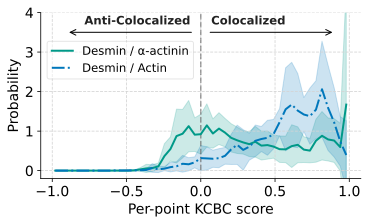

In [18]:
savepath = "../../figures/3b"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)